<a href="https://colab.research.google.com/github/olexvysotina-cell/ML/blob/main/%D0%9B%D0%A02_2_%D0%92%D0%B8%D1%81%D0%BE%D1%82%D1%96%D0%BD%D0%B0_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
titanic_df = pd.read_csv("titanic-selected-columns.csv")

1. Вивести 5 перших рядків датасету

In [ ]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500


2. Визначити розмір датасету

In [ ]:
titanic_df.shape

(891, 10)

3. Перевірити додаткові відомості по датасету

In [ ]:
titanic_df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
dtypes: float64(2), int64(5), object(3)
memory usage: 69.7+ KB


In [ ]:
titanic_df.nunique()

,0
PassengerId,891
Survived,2
Pclass,3
Name,891
Sex,2
Age,88
SibSp,7
Parch,7
Ticket,681
Fare,248


4. Перевірити наявність пропущених значень. При наявності замінити на середнє значення чи медіану

In [ ]:
titanic_df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
titanic_df = titanic_df.fillna(titanic_df.median(numeric_only = True))

5. Знову перевірити наявність пропущених значень

In [ ]:
titanic_df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


6. Ще раз вивести датасет

In [ ]:
titanic_df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500
...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28.0,1,2,W./C. 6607,23.4500
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000


7.Перевірити наявність дублікатів

In [ ]:
titanic_df.duplicated().sum()

np.int64(0)

8. Провести описову статистику

In [ ]:
titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


9. Обчислити кореляцію

In [ ]:
titanic_df.corr(numeric_only=True)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


10. Порівняти співвідношення за колонкою "Survived"

In [ ]:
(titanic_df["Survived"].value_counts(normalize=True) * 100).round(2)

,proportion
Survived,
0,61.62
1,38.38


11. Порівняти скільки в середньому людей вижило за статтю

In [ ]:
(titanic_df.groupby("Sex")["Survived"].mean() * 100).round(2)

,Survived
Sex,
female,74.20
male,18.89


12. Порівняти за класом

In [ ]:
(titanic_df.groupby("Pclass")["Survived"].mean() * 100).round(2)

,Survived
Pclass,
1,62.96
2,47.28
3,24.24


13. Порівняння за віком

In [ ]:
titanic_df.groupby("Survived")["Age"].mean()

,Age
Survived,
0,30.028233
1,28.291433


14. Діаграма розподілу пасажирів за віком

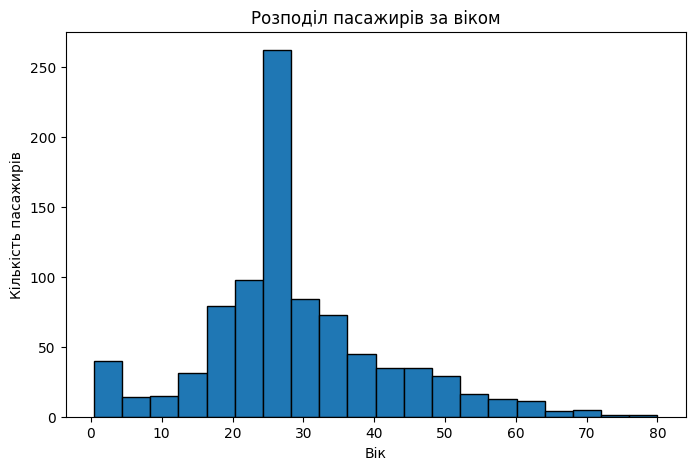

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(titanic_df["Age"], bins=20, edgecolor="black")

plt.title("Розподіл пасажирів за віком")
plt.xlabel("Вік")
plt.ylabel("Кількість пасажирів")

plt.show()

15. Діаграма кількості пасажирів за статтю

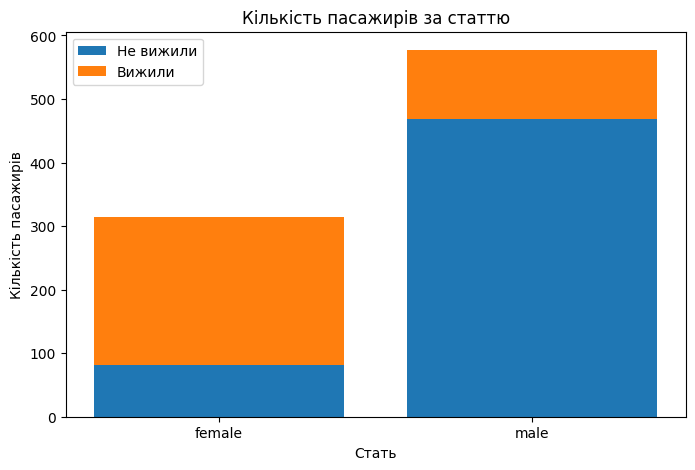

In [ ]:
survived = titanic_df[titanic_df["Survived"] == 1]["Sex"].value_counts()
not_survived = titanic_df[titanic_df["Survived"] == 0]["Sex"].value_counts()

sexes = ["female", "male"]

plt.figure(figsize=(8, 5))

plt.bar(sexes, not_survived.reindex(sexes), label="Не вижили")
plt.bar(
    sexes,
    survived.reindex(sexes),
    bottom=not_survived.reindex(sexes),
    label="Вижили"
)

plt.title("Кількість пасажирів за статтю")
plt.xlabel("Стать")
plt.ylabel("Кількість пасажирів")
plt.legend()

plt.show()

16. Діаграма частки виживання за класом квитка

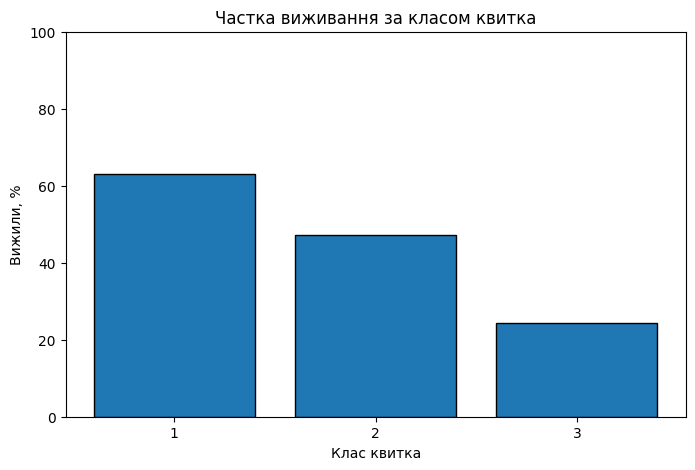

In [ ]:
survival_by_class = titanic_df.groupby("Pclass")["Survived"].mean() * 100

plt.figure(figsize=(8, 5))

plt.bar(
    survival_by_class.index,
    survival_by_class.values,
    edgecolor="black"
)

plt.title("Частка виживання за класом квитка")
plt.xlabel("Клас квитка")
plt.ylabel("Вижили, %")
plt.xticks([1, 2, 3])
plt.ylim(0, 100)

plt.show()

In [4]:
books_df = pd.read_csv("bestsellers with categories.csv")

In [5]:
books_df.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


In [6]:
books_df.shape

(550, 7)

In [7]:
books_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    object 
 1   Author       550 non-null    object 
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 30.2+ KB


In [8]:
books_df.dtypes

,0
Name,object
Author,object
User Rating,float64
Reviews,int64
Price,int64
Year,int64
Genre,object


In [9]:
books_df.nunique()

,0
Name,351
Author,248
User Rating,14
Reviews,346
Price,40
Year,11
Genre,2


In [10]:
books_df.describe()

,User Rating,Reviews,Price,Year
count,550.000000,550.000000,550.000000,550.000000
mean,4.618364,11953.281818,13.100000,2014.000000
std,0.226980,11731.132017,10.842262,3.165156
min,3.300000,37.000000,0.000000,2009.000000
25%,4.500000,4058.000000,7.000000,2011.000000
50%,4.700000,8580.000000,11.000000,2014.000000
75%,4.800000,17253.250000,16.000000,2017.000000
max,4.900000,87841.000000,105.000000,2019.000000


In [11]:
books_df['Genre'].unique()

array(['Non Fiction', 'Fiction'], dtype=object)

In [12]:
(books_df["Genre"].value_counts())

,count
Genre,
Non Fiction,310
Fiction,240


In [13]:
books_df.isna().sum()

,0
Name,0
Author,0
User Rating,0
Reviews,0
Price,0
Year,0
Genre,0


In [14]:
books_df.duplicated().sum()

np.int64(0)

In [15]:
books_df.sort_values("User Rating", ascending=False).head(5)

,Name,Author,User Rating,Reviews,Price,Year,Genre
521,Unfreedom of the Press,Mark R. Levin,4.9,5956,11,2019,Non Fiction
420,The Legend of Zelda: Hyrule Historia,Patrick Thorpe,4.9,5396,20,2013,Fiction
248,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2015,Fiction
247,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2014,Fiction
246,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2013,Fiction


In [16]:
books_df.sort_values("Reviews", ascending=False).head(5)

,Name,Author,User Rating,Reviews,Price,Year,Genre
534,Where the Crawdads Sing,Delia Owens,4.8,87841,15,2019,Fiction
382,The Girl on the Train,Paula Hawkins,4.1,79446,18,2015,Fiction
383,The Girl on the Train,Paula Hawkins,4.1,79446,7,2016,Fiction
33,Becoming,Michelle Obama,4.8,61133,11,2019,Non Fiction
32,Becoming,Michelle Obama,4.8,61133,11,2018,Non Fiction


In [17]:
books_df.corr(numeric_only=True)

,User Rating,Reviews,Price,Year
User Rating,1.000000,-0.001729,-0.133086,0.242383
Reviews,-0.001729,1.000000,-0.109182,0.263560
Price,-0.133086,-0.109182,1.000000,-0.153979
Year,0.242383,0.263560,-0.153979,1.000000


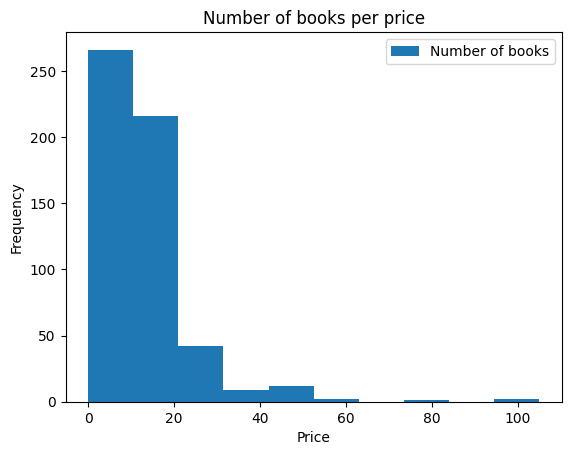

In [18]:
books_df['Price'].plot(kind='hist', label='Number of books')
plt.xlabel('Price')
plt.title('Number of books per price')
plt.legend()
plt.show()

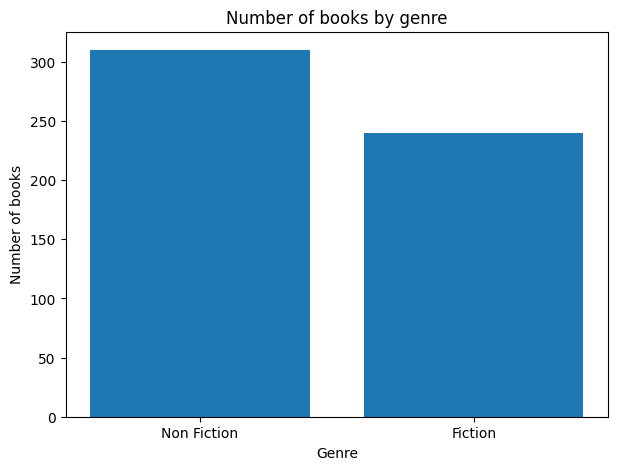

In [19]:
genre_counts = books_df["Genre"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(genre_counts.index, genre_counts.values)
plt.title("Number of books by genre")
plt.xlabel("Genre")
plt.ylabel("Number of books")
plt.show()

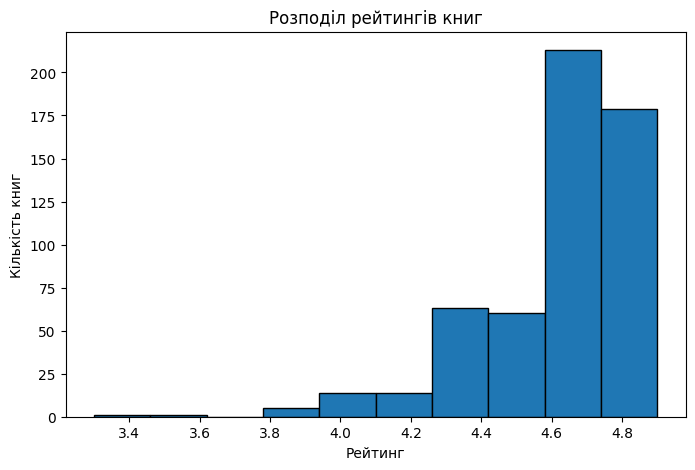

In [20]:
plt.figure(figsize=(8, 5))
plt.hist(books_df["User Rating"], bins=10, edgecolor="black")
plt.title("Розподіл рейтингів книг")
plt.xlabel("Рейтинг")
plt.ylabel("Кількість книг")
plt.show()

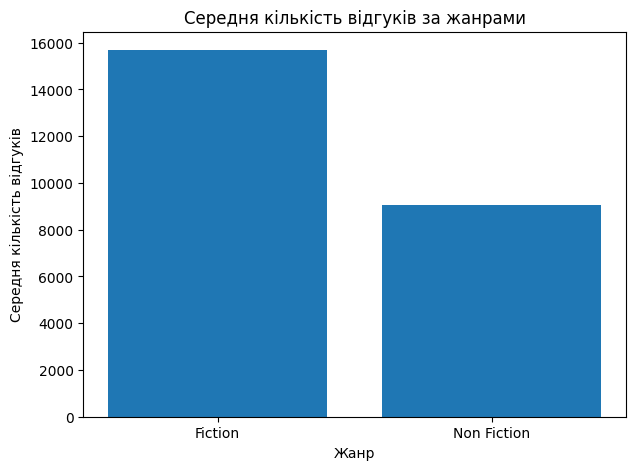

In [21]:
genre_reviews = books_df.groupby("Genre")["Reviews"].mean()

plt.figure(figsize=(7, 5))
plt.bar(genre_reviews.index, genre_reviews.values)
plt.title("Середня кількість відгуків за жанрами")
plt.xlabel("Жанр")
plt.ylabel("Середня кількість відгуків")
plt.show()